
# DeepTrace AI
## Deepfake Image Detection — Model Development & Evaluation

> **An EfficientNetB0-based deep learning approach for detecting AI-generated facial images.**

This notebook documents the model development, training, fine-tuning, and evaluation pipeline of **DeepTrace AI**, a deepfake image detection system designed to distinguish between authentic facial images and AI-generated synthetic faces.

The implementation uses **transfer learning with EfficientNetB0**, leveraging ImageNet-pretrained visual representations and adapting them to a binary real-versus-fake classification task.

### Project Objectives

- Develop a deep learning model capable of identifying AI-generated facial images.
- Leverage transfer learning to reduce computational requirements and training time.
- Apply a structured two-stage training strategy for model adaptation.
- Evaluate classification performance using multiple statistical metrics.
- Analyze model predictions through graphical visualizations and error analysis.

### Model Overview

| Component | Configuration |
|---|---|
| Model Architecture | EfficientNetB0 |
| Pretrained Weights | ImageNet |
| Task | Binary Image Classification |
| Input Resolution | 224 × 224 |
| Output Activation | Sigmoid |
| Optimizer | Adam |
| Loss Function | Binary Cross-Entropy |
| Training Strategy | Transfer Learning + Fine-Tuning |
| Framework | TensorFlow / Keras |

---

**Notebook Scope:** This notebook focuses on model development and experimental evaluation. It does not cover the complete DeepTrace AI application interface or deployment pipeline.



## 1. Environment Setup & Configuration

This section initializes the development environment and imports the libraries required for model development, dataset processing, training, and evaluation.

### Technologies Used

- **TensorFlow & Keras:** Deep learning framework and model implementation.
- **EfficientNetB0:** Pretrained convolutional neural network architecture.
- **NumPy:** Numerical operations and array processing.
- **Matplotlib & Seaborn:** Training visualization and performance analysis.
- **Scikit-learn:** Classification metrics and evaluation utilities.

### Experimental Configuration

The model uses a standardized input resolution of 224 × 224 pixels and a batch size of 64.

A fixed random seed is configured to improve experimental reproducibility. Mixed-precision computation is enabled to improve training efficiency on supported GPU hardware.

**Important:** Mixed-precision training is hardware-dependent and is particularly beneficial on compatible NVIDIA GPUs.


In [23]:
import os, json, warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef,
                             confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings('ignore')

IMG_SIZE   = (224, 224)
BATCH_SIZE = 64
SEED       = 42
DATA_DIR   = '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/'
CLASS_NAMES = ['real', 'fake']      # real=0, fake=1  ->  model output = P(fake)

keras.utils.set_random_seed(SEED)
keras.mixed_precision.set_global_policy('mixed_float16')   # faster on T4

print("TF:", tf.__version__, "| Keras:", keras.__version__)
print("GPU Detected" if tf.config.list_physical_devices('GPU') else "No GPU detected")

TF: 2.21.0 | Keras: 3.13.2
GPU Detected



## 2. Dataset Preparation & Input Pipeline

### Dataset: 140K Real and Fake Faces

The model uses the **140K Real and Fake Faces** dataset, which contains two categories of facial images:

- **Real:** Authentic facial photographs.
- **Fake:** Artificially generated facial images.

The dataset is organized into three separate subsets:

| Subset | Purpose |
|---|---|
| Training | Learning model parameters |
| Validation | Monitoring generalization during training |
| Testing | Independent final performance evaluation |

### Image Preprocessing

Before entering the model, images are resized to 224 × 224 pixels to maintain a consistent input shape.

The input pipeline uses TensorFlow's `image_dataset_from_directory()` utility to automatically load images and assign binary labels based on their directory structure.

### Data Augmentation

Lightweight augmentation is applied to the training dataset:

- Random horizontal flipping.
- Random contrast adjustment.

These transformations introduce limited visual variation during training and help reduce dependence on specific image appearances.

Augmentation is applied only to the training subset. Validation and test images remain unaugmented.

### Pipeline Optimization

The TensorFlow data pipeline uses parallel mapping and prefetching with `AUTOTUNE` to improve data-loading efficiency and reduce input bottlenecks during model training.

**Label Encoding:**

- `0` → Real
- `1` → Fake


In [24]:
AUTOTUNE = tf.data.AUTOTUNE

def load_split(split, training):
    ds = keras.utils.image_dataset_from_directory(
        DATA_DIR + split + '/', labels='inferred', label_mode='binary',
        class_names=CLASS_NAMES, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=training, seed=SEED)
    if training:
        def augment(x, y):               # pixel-level only: no rotation/zoom, which would blur GAN artifacts
            x = tf.image.random_flip_left_right(x)
            x = tf.image.random_contrast(x, 0.9, 1.1)
            return tf.clip_by_value(x, 0., 255.), y
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = load_split('train', True)
val_ds   = load_split('valid', False)
test_ds  = load_split('test',  False)

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.



## 3. Model Architecture — EfficientNetB0

### Transfer Learning Approach

DeepTrace AI uses **EfficientNetB0**, a convolutional neural network architecture pretrained on the ImageNet dataset.

Instead of training an entire deep learning network from random initialization, the implementation reuses pretrained visual feature representations and adapts them to the deepfake detection task.

EfficientNetB0 provides a computationally efficient architecture with a strong feature extraction capability, making it suitable for transfer learning.

### Architecture Overview

The classification network consists of the following components:

1. **Input Layer:** Accepts RGB facial images of dimensions 224 × 224 × 3.
2. **EfficientNetB0 Backbone:** Extracts visual representations using pretrained convolutional layers.
3. **Global Average Pooling:** Converts spatial feature maps into a compact feature vector.
4. **Dense Layer:** A fully connected layer containing 512 neurons with ReLU activation.
5. **Dropout Layer:** Applies a dropout rate of 0.3 to help reduce overfitting.
6. **Output Layer:** A single neuron with sigmoid activation generates the probability of an image belonging to the fake class.

### Binary Classification

The final sigmoid output represents:

\[
P(\text{Fake}\mid x)
\]

The prediction is interpreted using a threshold of 0.5:

- Probability greater than 0.5 → Fake
- Probability less than or equal to 0.5 → Real

### Training Strategy

The model follows a two-stage transfer learning strategy:

- **Stage 1:** Train the newly added classification head while keeping the pretrained backbone frozen.
- **Stage 2:** Fine-tune the pretrained backbone using a lower learning rate to adapt its learned representations to the target classification task.

This approach provides a balance between reusing pretrained knowledge and learning task-specific features.


In [25]:
def build_model(weights='imagenet'):
    base = EfficientNetB0(weights=weights, include_top=False, input_shape=IMG_SIZE + (3,))
    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    return keras.Model(base.input, out), base

def compile_model(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.AUC(name='auc'),
                       keras.metrics.Precision(name='precision'),
                       keras.metrics.Recall(name='recall')])

model, base_model = build_model()
base_model.trainable = False
compile_model(model, 1e-3)
print("Model Built Successfully")
model.summary(show_trainable=False) if False else print(f"Params: {model.count_params():,}")

Model Built Successfully
Params: 4,705,956



## 4. Stage 1 — Classification Head Training

### Frozen Feature Extraction

During the first training stage, the EfficientNetB0 backbone is frozen.

This prevents updates to the pretrained feature extraction layers while allowing the newly added classification head to learn the distinction between real and AI-generated facial images.

### Configuration

| Parameter | Value |
|---|---|
| Backbone | Frozen |
| Learning Rate | 0.001 |
| Optimizer | Adam |
| Loss Function | Binary Cross-Entropy |
| Epochs | 2 |

### Training Objective

The primary objective is to adapt the newly initialized dense classification layers to the target dataset without immediately modifying the pretrained feature extractor.

A model checkpoint is maintained using validation accuracy, ensuring that the best-performing model weights are preserved during training.

The resulting model provides the initialization point for the subsequent fine-tuning stage.


In [26]:
EPOCHS_HEAD, EPOCHS_FT = 2, 8

checkpoint = ModelCheckpoint('best_deepfake_model.keras', monitor='val_accuracy',
                             mode='max', save_best_only=True, verbose=1)

h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=[checkpoint])

Epoch 1/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.7990 - auc: 0.8816 - loss: 0.4258 - precision: 0.7911 - recall: 0.8105
Epoch 1: val_accuracy improved from None to 0.86670, saving model to best_deepfake_model.keras

Epoch 1: finished saving model to best_deepfake_model.keras
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 228s 132ms/step - accuracy: 0.8335 - auc: 0.9151 - loss: 0.3692 - precision: 0.8260 - recall: 0.8449 - val_accuracy: 0.8667 - val_auc: 0.9530 - val_loss: 0.3079 - val_precision: 0.8160 - val_recall: 0.9469
Epoch 2/2
1562/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.8750 - auc: 0.9488 - loss: 0.2891 - precision: 0.8687 - recall: 0.8827
Epoch 2: val_accuracy improved from 0.86670 to 0.90710, saving model to best_deepfake_model.keras

Epoch 2: finished saving model to best_deepfake_model.keras
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 178s 114ms/step - accuracy: 0.8806 - auc: 0.9524 - loss: 0.2787 - precision: 0.8747 - recall: 0.8885 - val_accuracy: 0.9071 - val_auc: 0.


## 5. Stage 2 — Fine-Tuning the Pretrained Network

### Domain Adaptation

After training the classification head, the EfficientNetB0 backbone is unfrozen to allow deeper adaptation to the real-versus-fake facial image classification task.

Fine-tuning enables the network to adjust its pretrained feature representations to the visual characteristics present in the target dataset.

### Fine-Tuning Configuration

| Parameter | Value |
|---|---|
| Backbone | Unfrozen |
| Learning Rate | 0.0001 |
| Maximum Additional Epochs | 8 |
| Optimizer | Adam |
| Learning Rate Scheduler | ReduceLROnPlateau |
| Early Stopping | Enabled |
| Checkpoint Monitoring | Validation Accuracy |

### Training Stabilization

Several mechanisms are used to improve training stability:

- **Batch Normalization Control:** Batch normalization layers remain non-trainable during fine-tuning.
- **Learning Rate Reduction:** The learning rate is reduced when validation loss stops improving.
- **Early Stopping:** Training stops when validation accuracy does not improve for the configured patience period.
- **Best Model Checkpoint:** The best validation-accuracy checkpoint is retained.

### Why Fine-Tuning?

The initial stage teaches the classification head to interpret pretrained features. Fine-tuning then allows the feature extractor itself to adapt to the target dataset.

The combination aims to improve task-specific learning while reducing the risk of unnecessarily disrupting pretrained representations.

**Note:** Eight epochs represent the maximum additional fine-tuning duration. Early stopping may terminate training sooner.


In [27]:
base_model.trainable = True
for l in base_model.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False

compile_model(model, 1e-4)

callbacks = [
    checkpoint,
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=1, min_lr=1e-6, verbose=1),
    EarlyStopping(monitor='val_accuracy', mode='max', patience=3, restore_best_weights=True),
]
h2 = model.fit(train_ds, validation_data=val_ds,
               initial_epoch=EPOCHS_HEAD, epochs=EPOCHS_HEAD + EPOCHS_FT, callbacks=callbacks)
print("Training Complete!")

Epoch 3/10


E0000 00:00:1794725250.139999     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794725261.110550     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1562/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.9430 - auc: 0.9857 - loss: 0.1433 - precision: 0.9408 - recall: 0.9448

E0000 00:00:1794725496.089537     151 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794725508.183857     151 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.9430 - auc: 0.9857 - loss: 0.1432 - precision: 0.9408 - recall: 0.9449
Epoch 3: val_accuracy improved from 0.90710 to 0.98935, saving model to best_deepfake_model.keras

Epoch 3: finished saving model to best_deepfake_model.keras
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 363s 164ms/step - accuracy: 0.9659 - auc: 0.9948 - loss: 0.0883 - precision: 0.9644 - recall: 0.9676 - val_accuracy: 0.9894 - val_auc: 0.9996 - val_loss: 0.0293 - val_precision: 0.9807 - val_recall: 0.9984 - learning_rate: 1.0000e-04
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.9891 - auc: 0.9991 - loss: 0.0300 - precision: 0.9880 - recall: 0.9903
Epoch 4: val_accuracy did not improve from 0.98935

Epoch 4: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 182s 117ms/step - accuracy: 0.9900 - auc: 0.9992 - loss: 0.0273 - precision: 0.9894 - recall: 0.9906 - val_accuracy: 0.9615 - val_auc: 0.9975 - v


## 6. Training Performance & Learning Curves

Training and validation performance are analyzed using four learning curves:

- **Loss:** Measures classification error during training.
- **Accuracy:** Measures the proportion of correctly classified samples.
- **AUC:** Measures the model's ability to distinguish between the two classes across classification thresholds.
- **Recall:** Measures the proportion of actual positive samples correctly identified.

Both training and validation curves are plotted to observe the model's learning behavior throughout the two training stages.

A vertical reference line indicates the transition from frozen-backbone training to fine-tuning.

### Interpretation

The learning curves help identify:

- Convergence behavior.
- Differences between training and validation performance.
- Potential overfitting or underfitting.
- Changes in learning behavior after fine-tuning.

These visualizations provide insight into the training process beyond a single final accuracy value.


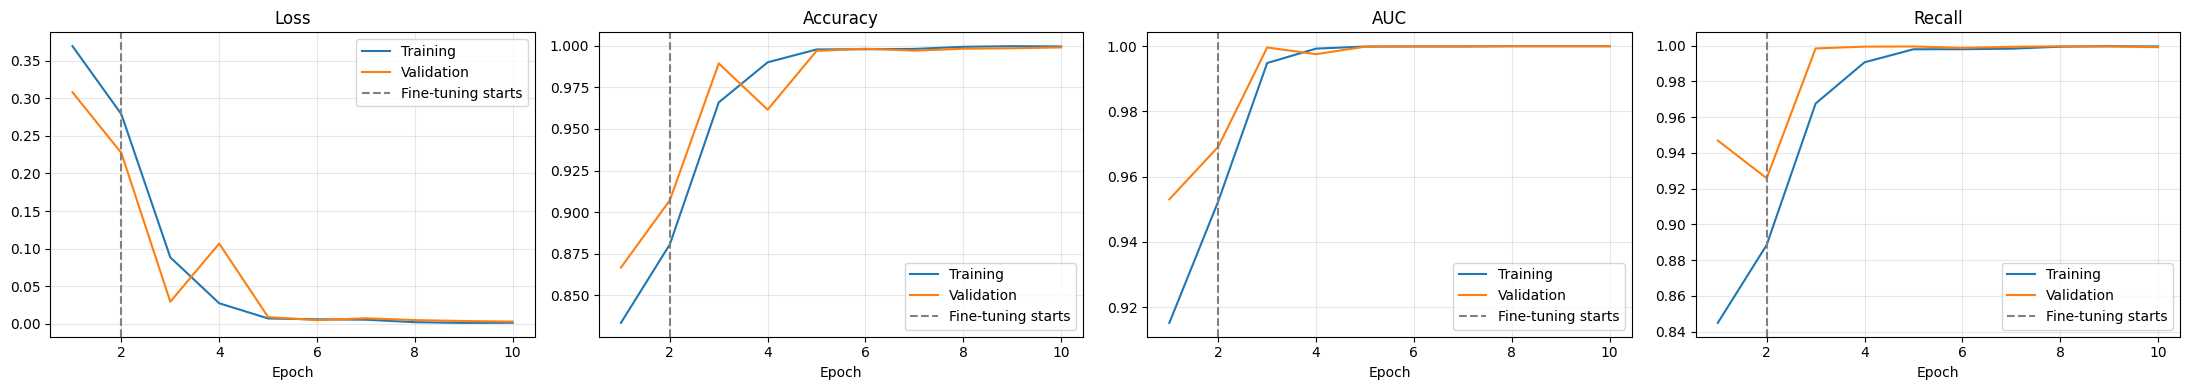

In [28]:
hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
ep = range(1, len(hist['loss']) + 1)
fig, ax = plt.subplots(1, 4, figsize=(22, 4))
for a, (m, t) in zip(ax, [('loss','Loss'), ('accuracy','Accuracy'), ('auc','AUC'), ('recall','Recall')]):
    a.plot(ep, hist[m], label='Training'); a.plot(ep, hist['val_'+m], label='Validation')
    a.axvline(EPOCHS_HEAD, ls='--'
## 7. Best Model Selection & Export

### Checkpoint Restoration

Following training, the best saved model checkpoint is loaded for subsequent evaluation.

The checkpoint is selected using validation accuracy, rather than relying exclusively on the weights from the final training epoch.

### Model Export

The selected model is saved in Keras native format:

`final_deepfake_model.keras`

This file contains the trained model architecture and learned weights, allowing the model to be loaded later for inference and integration into the DeepTrace AI application.

### Purpose

Separating model training from model inference allows the trained model to be reused without repeating the entire training process for every prediction.

**Exported Artifact:** `final_deepfake_model.keras`
, c='gray', label='Fine-tuning starts')
    a.set_title(t); a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('training_curves.png', dpi=200); plt.show()


## 7. Best Model Selection & Export

### Checkpoint Restoration

Following training, the best saved model checkpoint is loaded for subsequent evaluation.

The checkpoint is selected using validation accuracy, rather than relying exclusively on the weights from the final training epoch.

### Model Export

The selected model is saved in Keras native format:

`final_deepfake_model.keras`

This file contains the trained model architecture and learned weights, allowing the model to be loaded later for inference and integration into the DeepTrace AI application.

### Purpose

Separating model training from model inference allows the trained model to be reused without repeating the entire training process for every prediction.

**Exported Artifact:** `final_deepfake_model.keras`


In [35]:
best = keras.models.load_model('best_deepfake_model.keras')
best.save('final_deepfake_model.keras')
model = best


## 8. Independent Test Set Evaluation

After model training and checkpoint restoration, the selected model is evaluated against the held-out test dataset.

The test dataset is used to assess the model's classification performance on samples that were not used for parameter optimization or validation-based checkpoint selection.

### Prediction Process

For each test batch:

1. Images are passed through the trained model.
2. The model generates a sigmoid probability for each image.
3. Actual labels and predicted probabilities are collected.
4. Predicted classes are determined using a 0.5 threshold.
5. Incorrectly classified samples are retained for subsequent error analysis.

### Prediction Output

The model produces a probability representing the likelihood that an input image belongs to the fake category.

This probability is used for both binary classification and threshold-independent evaluation.

The collected predictions form the basis for the quantitative evaluation and visual analysis in the following sections.


In [36]:
y_true, y_prob, wrong = [], [], []
for x, y in test_ds:
    p = model.predict_on_batch(x).ravel()
    y = y.numpy().ravel().astype(int)
    y_prob.append(p); y_true.append(y)
    for img, yt, pp in zip(x.numpy(), y, p):
        if int(pp > 0.5) != yt and len(wrong) < 16:
            wrong.append((img.astype('uint8'), yt, pp))
y_true = np.concatenate(y_true); y_prob = np.concatenate(y_prob)
y_pred = (y_prob > 0.5).astype(int)


## 9. Quantitative Model Evaluation

Model performance is evaluated using multiple classification metrics to provide a more comprehensive assessment than accuracy alone.

### Evaluation Metrics

| Metric | Description |
|---|---|
| Accuracy | Overall proportion of correctly classified images. |
| Precision | Proportion of predicted fake images that are actually fake. |
| Recall | Proportion of actual fake images correctly detected. |
| Specificity | Proportion of actual real images correctly identified. |
| F1-Score | Harmonic mean of precision and recall. |
| ROC-AUC | Measures discrimination ability across classification thresholds. |
| Average Precision | Summarizes the precision-recall relationship. |
| Matthews Correlation Coefficient | Measures overall binary classification quality while considering all four confusion matrix outcomes. |

### Why Multiple Metrics?

In deepfake detection, both types of classification errors are important:

- **False Positive:** An authentic image is incorrectly classified as fake.
- **False Negative:** A fake image is incorrectly classified as real.

Accuracy alone does not adequately describe these two error types.

Therefore, precision, recall, specificity, F1-score, and MCC are included to provide a broader evaluation of model behavior.

### Classification Report

A class-wise classification report is also generated to examine the model's performance separately for real and fake images.

The computed evaluation metrics are additionally exported to `metrics.json` for future reference.

**Evaluation Principle:** All final performance metrics should be interpreted using the held-out test dataset, not training accuracy.


In [37]:
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
metrics = {
    'accuracy':      accuracy_score(y_true, y_pred),
    'precision':     precision_score(y_true, y_pred),
    'recall':        recall_score(y_true, y_pred),
    'specificity':   tn / (tn + fp),
    'f1':            f1_score(y_true, y_pred),
    'roc_auc':       roc_auc_score(y_true, y_prob),
    'avg_precision': average_precision_score(y_true, y_prob),
    'mcc':           matthews_corrcoef(y_true, y_pred),
}
print(f"Final Test Accuracy: {metrics['accuracy']*100:.2f}%\n")
for k, v in metrics.items(): print(f"{k:>14}: {v:.4f}")
print("\n", classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
json.dump({k: float(v) for k, v in metrics.items()}, open('metrics.json', 'w'), indent=2)

Final Test Accuracy: 99.88%

      accuracy: 0.9988
     precision: 0.9982
        recall: 0.9993
   specificity: 0.9982
            f1: 0.9988
       roc_auc: 1.0000
 avg_precision: 1.0000
           mcc: 0.9975

               precision    recall  f1-score   support

        real     0.9993    0.9982    0.9987     10000
        fake     0.9982    0.9993    0.9988     10000

    accuracy                         0.9988     20000
   macro avg     0.9988    0.9988    0.9987     20000
weighted avg     0.9988    0.9988    0.9987     20000




## 10. Visual Performance Analysis

Quantitative metrics are complemented by graphical evaluation to provide a more intuitive understanding of the model's classification behavior.

This section contains four visualizations.

### 1. Confusion Matrix

The confusion matrix displays the number of correct and incorrect predictions for both classes.

It helps identify false positives and false negatives and provides a direct view of classification errors.

### 2. Normalized Confusion Matrix

The normalized confusion matrix represents classification outcomes as proportions of actual class instances.

This makes it easier to compare class-wise performance independently of the number of samples in each class.

### 3. Receiver Operating Characteristic (ROC) Curve

The ROC curve illustrates the relationship between the true positive rate and false positive rate across different classification thresholds.

The Area Under the Curve (AUC) summarizes the model's ability to distinguish between real and fake images.

### 4. Precision-Recall Curve

The precision-recall curve examines the relationship between precision and recall across different classification thresholds.

Average Precision (AP) provides a summary of this relationship.

### Analytical Significance

Together, these visualizations help assess the model's classification reliability, discrimination capability, and potential weaknesses.


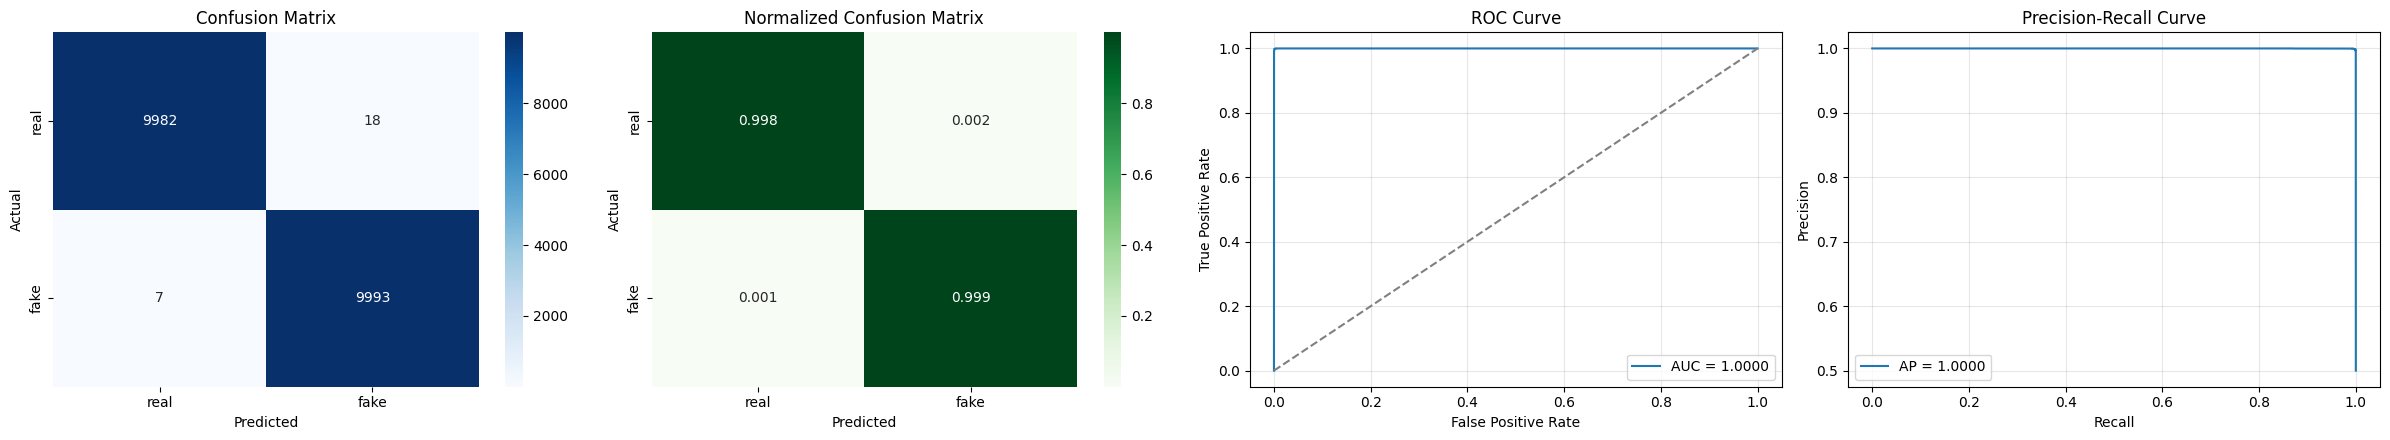

In [40]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 4, figsize=(24, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set(title='Confusion Matrix', xlabel='Predicted', ylabel='Actual')
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.3f', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
ax[1].set(title='Normalized Confusion Matrix', xlabel='Predicted', ylabel='Actual')

fpr, tpr, _ = roc_curve(y_true, y_prob)
ax[2].plot(fpr, tpr, label=f"AUC = {metrics['roc_auc']:.4f}"); ax[2].plot([0,1],[0,1],'--',c='gray')
ax[2].set(title='ROC Curve', xlabel='False Positive Rate', ylabel='True Positive Rate'); ax[2].legend(); ax[2].grid(alpha=.3)

pr, rc, _ = precision_recall_curve(y_true, y_prob)
ax[3].plot(rc, pr, label=f"AP = {metrics['avg_precision']:.4f}")
ax[3].set(title='Precision-Recall Curve', xlabel='Recall', ylabel='Precision'); ax[3].legend(); ax[3].grid(alpha=.3)
plt.tight_layout(); plt.savefig('evaluation_plots.png', dpi=200); plt.show()


## 11. Prediction Confidence & Error Analysis

A deeper examination of model predictions is performed using probability distributions and incorrectly classified test samples.

### Prediction Confidence Distribution

The predicted fake probabilities are visualized separately for:

- Actual real images.
- Actual fake images.

A threshold of 0.5 is displayed to indicate the decision boundary used for binary classification.

This visualization helps examine how confidently the model separates the two categories and whether their predicted probability distributions overlap.

### Misclassified Sample Analysis

Incorrectly classified test images are collected and displayed for qualitative inspection.

For each displayed sample, the visualization includes:

- The original test image.
- Its actual class label.
- Its predicted fake probability.

### Purpose of Error Analysis

Inspecting incorrect predictions helps identify possible limitations in the model's learned representations.

It also provides a useful starting point for investigating difficult samples, visual similarities between categories, and potential sources of classification errors.

**Important:** Misclassified examples are selected from the test set for analysis. Their visual inspection does not independently establish the underlying reason for a prediction error.


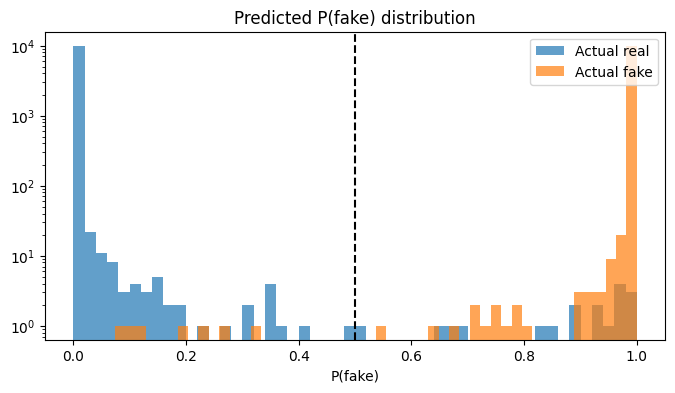

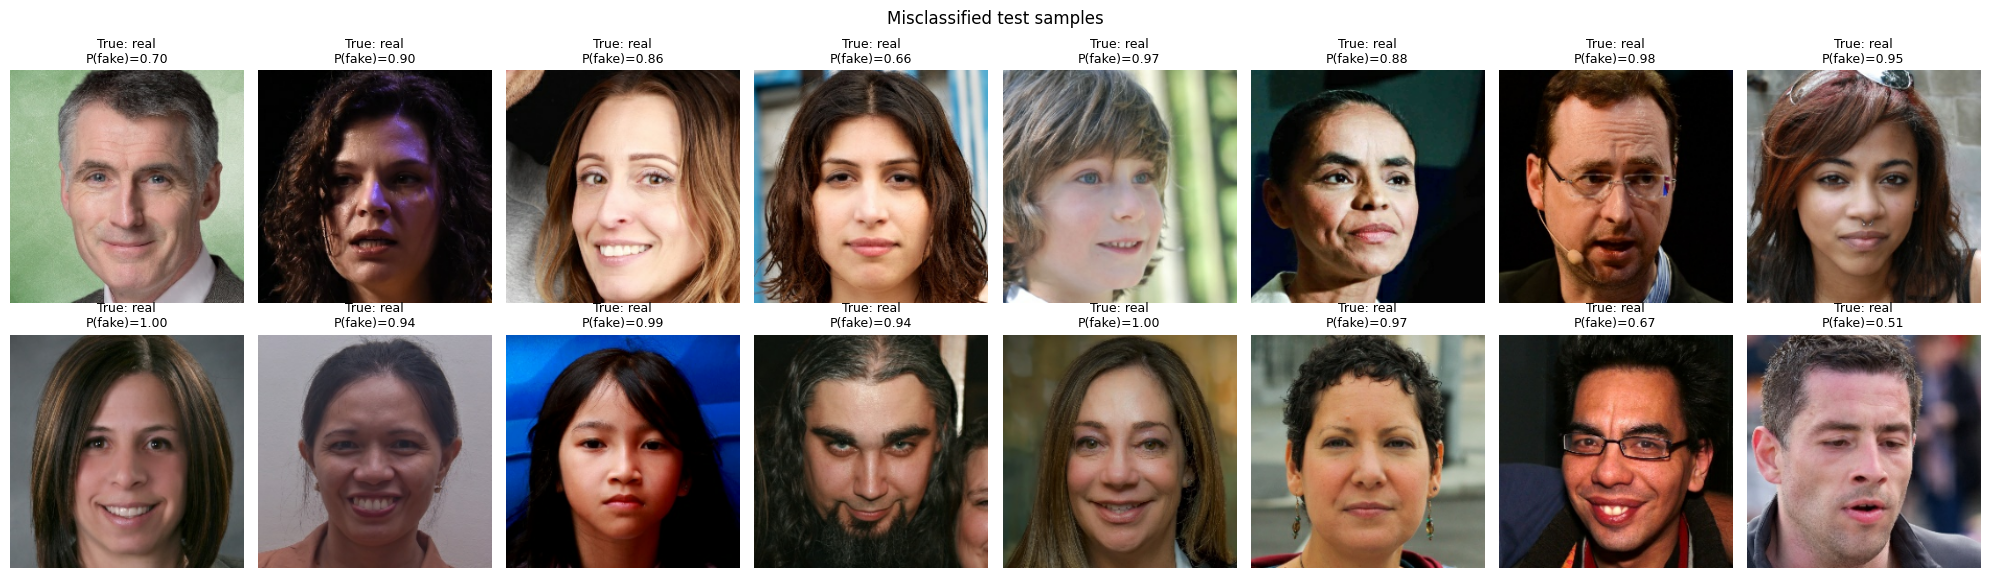

In [39]:
plt.figure(figsize=(8, 4))
plt.hist(y_prob[y_true == 0], bins=50, alpha=.7, label='Actual real')
plt.hist(y_prob[y_true == 1], bins=50, alpha=.7, label='Actual fake')
plt.axvline(0.5, c='k', ls='--'); plt.yscale('log')
plt.title('Predicted P(fake) distribution'); plt.xlabel('P(fake)'); plt.legend()
plt.savefig('confidence_hist.png', dpi=200); plt.show()

if wrong:
    fig, axs = plt.subplots(2, 8, figsize=(20, 6))
    for a, (img, yt, p) in zip(axs.ravel(), wrong):
        a.imshow(img); a.axis('off'); a.set_title(f"True: {CLASS_NAMES[yt]}\nP(fake)={p:.2f}", fontsize=9)
    plt.suptitle('Misclassified test samples'); plt.tight_layout()
    plt.savefig('misclassified.png', dpi=200); plt.show()


# 12. Conclusion & Future Scope

## Conclusion

This notebook presents the development and evaluation of an EfficientNetB0-based deep learning model for binary deepfake image detection.

The implementation combines ImageNet-based transfer learning with a two-stage training strategy to adapt pretrained visual representations to real-versus-fake facial image classification.

The model development pipeline includes dataset preparation, lightweight augmentation, classification head training, backbone fine-tuning, checkpoint selection, quantitative evaluation, and qualitative error analysis.

Multiple evaluation metrics and graphical visualizations are incorporated to provide a broader understanding of model performance and classification behavior.

The trained model is exported in Keras format for subsequent reuse within the DeepTrace AI application.

## Future Scope

Potential directions for further development include:

1. **Improved Generalization:** Evaluate performance on additional datasets and previously unseen image-generation methods.
2. **Threshold Optimization:** Investigate alternative classification thresholds based on validation performance and application requirements.
3. **Explainable AI:** Incorporate techniques such as Grad-CAM to visualize image regions influencing model predictions.
4. **Robustness Testing:** Study model behavior under image compression, resizing, noise, and other image transformations.
5. **Model Optimization:** Explore inference optimization for resource-constrained deployment environments.
6. **Application Integration:** Integrate the trained model into the DeepTrace AI interface for practical image analysis.

---

### Final Note

DeepTrace AI is intended as an AI-assisted deepfake detection system. Model predictions should be interpreted as probabilistic classifications rather than definitive proof of image authenticity.

**Project:** DeepTrace AI  
**Task:** Real vs. AI-Generated Facial Image Classification  
**Architecture:** EfficientNetB0  
**Framework:** TensorFlow / Keras
